# STATE Codex R2 — Sampling support, prospective dose displacement and checkpoint sensitivity

All custom calculations are executable inline. Run the six sections in order. Model evaluation uses the pinned public STATE releases. Use Python 3.11 with numpy 1.26.4, pandas 2.2.2, scipy 1.13.1, pyarrow 16.1.0, matplotlib 3.9.4, h5py 3.11.0, fsspec, aiohttp, IPython and ipykernel. `STATE_R2_INPUTS` may point at a verified raw-input cache.

## 1. Data source and acquisition

The URLs, sizes and SHA-256 values below identify the public input objects.

In [1]:
from pathlib import Path
import os,json,hashlib,time,platform,urllib.request,urllib.parse,ast,tomllib,re,zipfile,itertools
os.environ['OMP_NUM_THREADS']='1';os.environ['OPENBLAS_NUM_THREADS']='1';os.environ['MKL_NUM_THREADS']='1'
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import fsspec,h5py
from scipy.stats import spearmanr,pearsonr,rankdata
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display,Image
START=time.time()
DATA=Path(os.environ.get('STATE_R2_INPUTS','state_r2_inputs')).resolve(); DATA.mkdir(parents=True,exist_ok=True)
ROOT=Path('test-04_outputs').resolve();ROOT.mkdir(parents=True,exist_ok=True)
CELLS={'C32':'C32','HOP62':'HOP62','HepG2/C3A':'HepG2-C3A','Hs 766T':'Hs 766T','PANC-1':'PANC-1'}
CTX=['k562','jurkat','hepg2','rpe1']

from io import BytesIO
from IPython.display import Image
def display_figure(figure):
    buffer=BytesIO()
    figure.savefig(buffer,format='png',dpi=140,bbox_inches='tight')
    display(Image(data=buffer.getvalue()))


In [2]:
SOURCES = [{'path': 'metadata/generalization.toml',
  'url': 'https://raw.githubusercontent.com/ArcInstitute/state/da4178c930dc917dac6b56faf10a33e21bd8e905/state_preprint_toml_files/tahoe_tomls/generalization.toml',
  'bytes': 150875,
  'sha256': 'eac16fb06052dec9d6842dfae04d5ca693b847e3432f719a975adce205707783'},
 {'path': 'ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/C32_results.csv',
  'bytes': 281263,
  'sha256': '9fee724f7d5dc46a3e0061e264347ce4c8c5c29b6c0dac2dc67303bcae25894a'},
 {'path': 'ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/HOP62_results.csv',
  'bytes': 269030,
  'sha256': '646052bbdb9844e1a2b94f19c095d0f5a07db9529010f41252c61ba228544d56'},
 {'path': 'ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 287583,
  'sha256': '9106d01893815fbf77d85f4e2351da8a607adedc74edb62cc452c110812b09a2'},
 {'path': 'ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/Hs 766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/Hs%20766T_results.csv',
  'bytes': 277100,
  'sha256': '80c38255fdce0444457f909d7ef9c2186a82c5476550bfe82604bd48896aae72'},
 {'path': 'ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 273025,
  'sha256': '5a40d67c26a428487d3b0f602b5b7a69006b5c4595eaaf0ffb5f44eaf5160239'},
 {'path': 'ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_results.csv',
  'bytes': 468674,
  'sha256': 'cfb3517443ea659341b6be94f8b6828ef912ce21e0f3a0be4f3c5b29cd2dbc79'},
 {'path': 'ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_results.csv',
  'bytes': 463111,
  'sha256': 'dedd141ec8fdff513a19cb46f3bb95b76372b117935620b02f50f2f8e339d33d'},
 {'path': 'ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 473841,
  'sha256': 'a3c6d89ea4f07e395aac68db6a36222ced41f6acea648e8e5d008cd5912cf0fb'},
 {'path': 'ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs '
          '766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs%20766T_results.csv',
  'bytes': 468068,
  'sha256': '4904a9d8a3ed52a2cccd9de85cd0eeec0277bcc07d184eefb8096395719a2746'},
 {'path': 'ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 464280,
  'sha256': '8483133246cf1dba89c76a94f8a407757f4714bff5c9534f66890fbfe3d7ec03'},
 {'path': 'ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_real_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_real_de.csv',
  'bytes': 387383572,
  'sha256': '19922ccec8820e43daa74dac907adeaa7b12d651308570650920762269f568d2'},
 {'path': 'ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv',
  'bytes': 468117,
  'sha256': 'a0de78f621e8c6dfc67ac6ab6acbbab65fbd3aaddf7e56732ed6f03569d39f94'},
 {'path': 'ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_real_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_real_de.csv',
  'bytes': 395844167,
  'sha256': '05c3fa4a991b1e94cdd991be01a787bd779c384d66760b70fbd569ffe5411063'},
 {'path': 'ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'bytes': 459434,
  'sha256': 'e3fef3287ccc5f38ac64c1c249915684a11dda7b38b43884b1f636cde792364a'},
 {'path': 'ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_real_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_real_de.csv',
  'bytes': 381547673,
  'sha256': 'a038a095e74641cf068dc048a5e4f619b572c5b0b97ff9a10c47931ab75db13b'},
 {'path': 'ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 479496,
  'sha256': '8f953408f94eadc1461851599a33e2a4f84e413621d5ee54a52a8746c2037691'},
 {'path': 'ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs 766T_real_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs%20766T_real_de.csv',
  'bytes': 389336629,
  'sha256': '7d9f9e651c57a4ebb11ee04c256dac7a8b642b4736d3499c75cefa39908469d5'},
 {'path': 'ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs 766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs%20766T_results.csv',
  'bytes': 466949,
  'sha256': 'b9ab34b3d93a414e5db0650aaad70fb9bc558abade0e4c4eb3322ab3e4a47080'},
 {'path': 'ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_real_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_real_de.csv',
  'bytes': 398029547,
  'sha256': '2b9ed18f2dae9d83dbfa910d9e7e2cac1da7ad0f73e43bed40b8daaf62a254c9'},
 {'path': 'ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 461203,
  'sha256': '2171a50b43d55ed6a5fae82c50685fd519b21b3a821872cb0e147a338d26a332'},
 {'path': 'metadata/tahoe_obs_metadata.parquet',
  'url': 'https://huggingface.co/datasets/tahoebio/Tahoe-100M/resolve/2dc57900b7981cfcf5e211527169a0b006546a95/metadata/obs_metadata.parquet',
  'bytes': 2293981573,
  'sha256': 'e51b24f3666f5f433c59ff01dd6fa33934627091455e89d929f2c1ddc87401fe'}]


In [3]:
def sha(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(8388608),b''):h.update(b)
    return h.hexdigest()
def checked(root,rel):
    x=next(x for x in SOURCES if x['path']==rel);p=DATA/rel
    if not p.exists() or p.stat().st_size!=x['bytes'] or sha(p)!=x['sha256']:raise ValueError('Input checksum mismatch: '+rel)
    return p
for x in SOURCES:
    p=DATA/x['path'];p.parent.mkdir(parents=True,exist_ok=True)
    if not p.exists():
        temp=p.with_suffix(p.suffix+'.part')
        req=urllib.request.Request(x['url'],headers={'User-Agent':'STATE-notebook/1.0'})
        with urllib.request.urlopen(req,timeout=180) as source,temp.open('wb') as target:
            while b:=source.read(8388608):target.write(b)
        if temp.stat().st_size!=x['bytes'] or sha(temp)!=x['sha256']:raise ValueError('Downloaded source identity mismatch: '+x['path'])
        temp.replace(p)
    checked(ROOT,x['path'])
print('Verified public input files:',len(SOURCES))


Verified public input files: 22


## 2. Data processing

Parse the exact drug, dose and unit identities. Aggregate treated-cell metadata over all cells. Control counts sum DMSO cells once for each technical plate represented by the condition.

In [4]:
def sha(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(8 * 1024 * 1024), b''):
            h.update(b)
    return h.hexdigest()

def dump(path, obj):
    p = Path(path)
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(json.dumps(obj, indent=2, default=lambda x: x.item() if isinstance(x, np.generic) else str(x), allow_nan=False) + '\n')

def zscore(x):
    x = np.asarray(x, dtype=float)
    s = x.std(ddof=0)
    if not s > 0:
        raise ValueError('Constant predictor')
    return (x - x.mean()) / s

def fisher(x):
    return np.arctanh(np.clip(np.asarray(x, float), -1 + 1e-07, 1 - 1e-07))

def cluster_fit(d, y, x, cluster, adjust=(), fixed=(), cluster_fixed=False, draws=10000, seed=20260715):
    cols = [y, x, cluster, *adjust, *fixed]
    d = d.dropna(subset=cols).copy()
    X = [np.ones(len(d)), zscore(d[x])]
    names = ['intercept', x]
    for c in adjust:
        v = np.asarray(d[c], float)
        if np.std(v) > 0:
            X.append(zscore(v))
            names.append(c)
    for c in fixed:
        for val in sorted(d[c].unique())[1:]:
            X.append((d[c] == val).astype(float).values)
            names.append(f'{c}={val}')
    X = np.column_stack(X)
    Y = d[y].to_numpy(float)
    groups = sorted(d[cluster].unique())
    codes = pd.Categorical(d[cluster], categories=groups).codes
    if cluster_fixed:
        for j in range(len(groups)):
            sel = codes == j
            X[sel] -= X[sel].mean(axis=0)
            Y[sel] -= Y[sel].mean()
        X = X[:, 1:]
        names = names[1:]
        axis_idx = 0
    else:
        axis_idx = 1
    gxx = np.zeros((len(groups), X.shape[1], X.shape[1]))
    gxy = np.zeros((len(groups), X.shape[1]))
    for j in range(len(groups)):
        sel = codes == j
        gxx[j] = X[sel].T @ X[sel]
        gxy[j] = X[sel].T @ Y[sel]
    coefficient = np.linalg.lstsq(X, Y, rcond=None)[0]
    rng = np.random.default_rng(seed)
    boot = []
    for start in range(0, draws, 100):
        n = min(100, draws - start)
        w = rng.multinomial(len(groups), np.full(len(groups), 1 / len(groups)), size=n)
        xx = np.einsum('bg,gij->bij', w, gxx)
        xy = w @ gxy
        for a, b in zip(xx, xy):
            boot.append(np.linalg.lstsq(a, b, rcond=None)[0][axis_idx])
    return (dict(n=len(d), clusters=len(groups), coefficient=float(coefficient[axis_idx]), ci95=np.quantile(boot, [0.025, 0.975]).tolist(), draws=draws, seed=seed, design_columns=names, cluster_fixed_effect=cluster_fixed, axis_standardization='population SD on all analyzed rows', coefficients=dict(zip(names, coefficient))), np.asarray(boot))

def curve(d, level, score, cluster, draws=10000, seed=20260715):
    groups = sorted(d[cluster].unique())
    levels = sorted(d[level].unique())
    rng = np.random.default_rng(seed)
    w = rng.multinomial(len(groups), np.full(len(groups), 1 / len(groups)), size=draws)
    rows = []
    boot = {}
    for v in levels:
        q = d[d[level] == v]
        g = q.groupby(cluster)[score].agg(['sum', 'count']).reindex(groups, fill_value=0)
        b = w @ g['sum'].values / (w @ g['count'].values)
        boot[str(v)] = b
        rows.append(dict(level=v, n=len(q), clusters=q[cluster].nunique(), mean=q[score].mean(), ci_low=np.quantile(b, 0.025), ci_high=np.quantile(b, 0.975)))
    return (pd.DataFrame(rows), boot)

def parse(s):
    a = ast.literal_eval(s)
    if len(a) != 1 or len(a[0]) != 3:
        raise ValueError(f'Unexpected condition {s}')
    drug, dose, unit = a[0]
    return (str(drug).strip(), float(dose), str(unit))

def controls(root):
    p = checked(root, 'metadata/tahoe_obs_metadata.parquet')
    out = root / 'computed/tahoe'
    out.mkdir(parents=True, exist_ok=True)
    data = ds.dataset(p, format='parquet')
    cols = ['cell_name', 'drugname_drugconc', 'plate', 'pcnt_mito', 'gene_count', 'tscp_count', 'pass_filter']
    d = data.to_table(columns=cols, filter=ds.field('cell_name').isin(list(CELLS))).to_pandas()
    for c in ['cell_name', 'drugname_drugconc', 'plate']:
        d[c] = d[c].astype(str)
    mapping = {x: parse(x) for x in d.drugname_drugconc.unique()}
    d['drug'] = d.drugname_drugconc.map(lambda x: mapping[x][0])
    d['dose'] = d.drugname_drugconc.map(lambda x: mapping[x][1])
    d = d.rename(columns={'cell_name': 'context'})
    g = d.groupby(['context', 'drug', 'dose'], observed=True).agg(n_treated=('drug', 'size'), mito=('pcnt_mito', 'mean'), gene_mean=('gene_count', 'mean'), umi_mean=('tscp_count', 'mean')).reset_index()
    cb = d[d.drug == 'DMSO_TF'].groupby(['context', 'plate'], observed=True).size()
    unique_plates = d[['context', 'drug', 'dose', 'plate']].drop_duplicates()
    unique_plates['n_control_plate'] = [cb.get((c, p), 0) for c, p in zip(unique_plates.context, unique_plates.plate)]
    cnt = unique_plates.groupby(['context', 'drug', 'dose'], observed=True).n_control_plate.sum().rename('n_control').reset_index()
    g = g.merge(cnt, on=['context', 'drug', 'dose'], validate='one_to_one')
    g.to_csv(out / 'condition_controls.csv', index=False)
    return g

In [5]:
controls_table=controls(ROOT)
display(controls_table.head())

,context,drug,dose,n_treated,mito,gene_mean,umi_mean,n_control
0,C32,(R)-Verapamil (hydrochloride),0.05,2180,0.054788,1162.405046,1768.183486,4178
1,C32,(R)-Verapamil (hydrochloride),0.50,1233,0.048386,911.892944,1277.640714,5082
2,C32,(R)-Verapamil (hydrochloride),5.00,4124,0.056329,1340.717992,2152.836566,8290
3,C32,(S)-Crizotinib,0.05,1974,0.046369,1010.403242,1492.146910,1662
4,C32,(S)-Crizotinib,0.50,1445,0.040158,1062.401384,1558.880277,3763


## 3. Axis definition and level construction

In [6]:
def cohort(root):
    p = checked(root, 'metadata/generalization.toml')
    t = tomllib.loads(p.read_text())
    sets = []
    for c in CELLS:
        sets.append({parse(x) for x in t['fewshot'][f'tahoe_holdout.{c}']['test']})
    common = set.intersection(*sets)
    drugs = sorted({x[0] for x in common if all(((x[0], v, 'uM') in common for v in [0.05, 0.5, 5.0]))})
    d = pd.DataFrame([(c, g, v, 'uM') for c in CELLS for g in drugs for v in [0.05, 0.5, 5.0]], columns=['context', 'drug', 'dose', 'unit'])
    d['weakness'] = -np.log10(d.dose)
    d['dose_level'] = d.dose.map({5.0: 1, 0.5: 2, 0.05: 3})
    out = root / 'computed/tahoe'
    out.mkdir(parents=True, exist_ok=True)
    d.to_csv(out / 'cohort.csv', index=False)
    dump(out / 'cohort_summary.json', dict(drugs=len(drugs), conditions=len(drugs) * 3, units=len(d), test_list_counts=dict(zip(CELLS, map(len, sets))), eligibility='intersection of five official test lists; complete fixed three-dose triplet per exact stripped drug name'))
    return d, [p]

cohort_table,_=cohort(ROOT)
display(cohort_table.groupby('dose').size())

dose
0.05    995
0.50    995
5.00    995
dtype: int64

Use the intersection of the five public test lists, requiring the complete 0.05, 0.5 and 5 μM triplet. Dose weakness is −log10(dose); levels increase from 5 to 0.05 μM. A sign criterion that requires a positive slope while predicting lower scores at weaker dose is contradictory; that formulation is retired before outcome testing.

In [7]:
support=cohort_table.merge(controls_table,on=['context','drug','dose'],validate='one_to_one')
support['sampling_weakness']=-np.log1p(support.n_treated)
ix=support.sort_values(['sampling_weakness','context','drug','dose'],kind='mergesort').index
support.loc[ix,'level']=np.floor(np.arange(len(ix))*5/len(ix)).astype(int)+1
display(support.groupby('level').agg(rows=('drug','size'),mean_cells=('n_treated','mean'),min_cells=('n_treated','min'),max_cells=('n_treated','max')))

,rows,mean_cells,min_cells,max_cells
level,,,,
1.0,597,4847.802345,3319,14192
2.0,597,2650.438861,2154,3318
3.0,597,1772.075377,1457,2154
4.0,597,1150.147404,881,1455
5.0,596,578.016779,1,881


## 4. Model results and released scores

The sampling, prospective displacement and checkpoint-family candidates depend on an eligible prospective comparison panel. This section does not substitute a different score population for an unscored candidate. The source inventory and cohort eligibility are shown explicitly.

## 5. Curves and controls

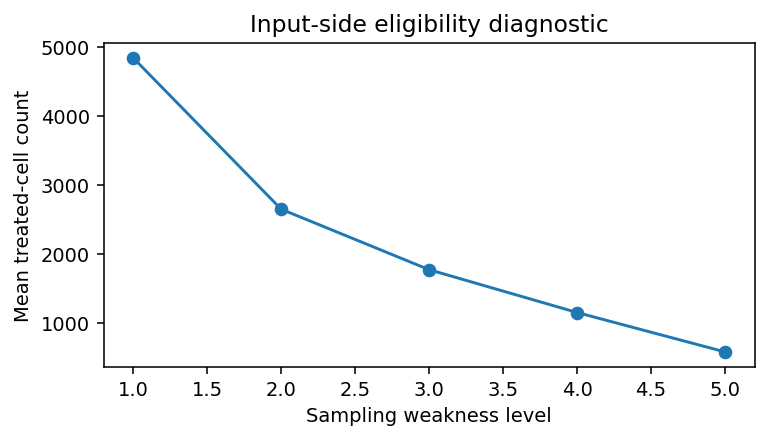

Eligible fixed dose cohort: 199 compounds; 2985 condition-context rows


In [8]:
levels=support.groupby('level').agg(mean_cells=('n_treated','mean'),units=('drug','size')).reset_index()
fig,ax=plt.subplots(figsize=(6,3));ax.plot(levels.level,levels.mean_cells,'o-');ax.set(xlabel='Sampling weakness level',ylabel='Mean treated-cell count',title='Input-side eligibility diagnostic');display_figure(fig);plt.close(fig)
print('Eligible fixed dose cohort:',cohort_table.drug.nunique(),'compounds;',len(cohort_table),'condition-context rows')

## 6. What the agent decided, and why

Close the sampling-support, prospective dose-displacement and checkpoint-family candidates without an outcome claim because their prospective comparison dependency is unavailable. The computed level and cohort tables are eligibility diagnostics, not performance curves.

In [9]:
record={'completed':True,'host':platform.node(),'elapsed_seconds':time.time()-START,'sources':SOURCES,'custom_external_code_used':False,'model_inference_performed':False}
(ROOT/'execution_record.json').write_text(json.dumps(record,indent=2))
print('Completed:',ROOT)

Completed: /ewsc/yektefai/spectra_runs/all_axes_inline_20261109/state/state-codex-r2/test-04_outputs
